# 零售企业销售数据分析：哪些业务在赚钱，哪些在亏钱？

**数据**：加拿大办公用品零售商 Superstore 订单明细，2009–2012 年，共 8,399 条订单记录、21 个字段（订单、客户、产品、物流、金额）。
来源：公开数据集 [curran/data](https://github.com/curran/data/tree/gh-pages/superstoreSales)

**分析目标**（站在业务负责人的角度）：
1. 整体销售和利润的走势如何？
2. 哪些品类 / 子品类贡献利润，哪些在亏钱？
3. 折扣力度和利润之间是什么关系？
4. 各区域表现差异在哪？
5. 客户价值是否集中（二八定律）？

**流程**：数据读取 → 数据清洗 → 探索分析 → 可视化 → 业务结论与建议

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

# 中文字体 + 统一图表风格
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'Microsoft YaHei', 'PingFang SC', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e'})
BLUE, ORANGE, AQUA, RED, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#a3a29c'
IMG = Path('images'); IMG.mkdir(exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(IMG / name, dpi=150, bbox_inches='tight')

## 1. 数据读取
原始文件使用老式 Mac 换行符（`\r`）和 Latin-1 编码，直接读会报错或乱码，需要显式指定。

In [2]:
raw = pd.read_csv('data/superstore_sales.csv', encoding='latin1', lineterminator='\r')
print(raw.shape)
raw.head(3)

(8400, 21)


,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3.0,10/13/2010,Low,6.0,261.54,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293.0,10/1/2012,High,49.0,10123.02,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293.0,10/1/2012,High,27.0,244.57,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012


## 2. 数据清洗
逐项检查：空行、缺失值、重复、类型、拼写错误、异常值。

In [3]:
print('每列缺失值：')
print(raw.isna().sum()[raw.isna().sum() > 0])
print('\n完全重复的行：', raw.duplicated().sum())

每列缺失值：
Order ID                 1
Order Date               1
Order Priority           1
Order Quantity           1
Sales                    1
Discount                 1
Ship Mode                1
Profit                   1
Unit Price               1
Shipping Cost            1
Customer Name            1
Province                 1
Region                   1
Customer Segment         1
Product Category         1
Product Sub-Category     1
Product Name             1
Product Container        1
Product Base Margin     64
Ship Date                1
dtype: int64

完全重复的行： 0


发现的问题和处理方式：

| 问题 | 处理 |
|---|---|
| 文件末尾 1 行全空 | 删除 |
| `Product Base Margin` 缺失 63 条 | 用同一子品类的中位数填充（同类产品毛利率相近） |
| 日期是字符串 | 转为日期类型，并计算发货天数 |
| 区域名拼写错误 `Prarie` | 更正为 `Prairie` |
| 订单号、数量是浮点数 | 转为整数 |

In [4]:
df = raw.dropna(how='all', subset=['Order ID']).copy()
df['Product Base Margin'] = df.groupby('Product Sub-Category')['Product Base Margin'].transform(lambda s: s.fillna(s.median()))
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
df['Ship Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Region'] = df['Region'].replace({'Prarie': 'Prairie'})
df[['Order ID', 'Order Quantity']] = df[['Order ID', 'Order Quantity']].astype(int)
df['Year'] = df['Order Date'].dt.year
df['Profit Margin'] = df['Profit'] / df['Sales']

print('清洗后：', df.shape, '| 剩余缺失值：', int(df.isna().sum().sum()))
print('发货天数范围：', df['Ship Days'].min(), '~', df['Ship Days'].max())
df[['Sales', 'Profit', 'Discount', 'Order Quantity']].describe().round(2)

清洗后： (8399, 24) | 剩余缺失值： 0
发货天数范围： 0 ~ 92


,Sales,Profit,Discount,Order Quantity
count,8399.00,8399.00,8399.00,8399.00
mean,1775.88,181.18,0.05,25.57
std,3585.05,1196.65,0.03,14.48
min,2.24,-14140.70,0.00,1.00
25%,143.20,-83.32,0.02,13.00
50%,449.42,-1.50,0.05,26.00
75%,1709.32,162.75,0.08,38.00
max,89061.05,27220.69,0.25,50.00


**一个值得注意的信号**：利润的中位数是负数（-1.50），也就是说**超过一半的订单是亏钱的**，公司整体盈利靠少数高利润订单撑着。下面逐层找原因。

## 3. 整体经营概况

In [5]:
kpi = pd.Series({
    '总销售额': df['Sales'].sum(),
    '总利润': df['Profit'].sum(),
    '整体利润率': df['Profit'].sum() / df['Sales'].sum(),
    '订单数': df['Order ID'].nunique(),
    '客户数': df['Customer Name'].nunique(),
    '亏损订单占比': (df['Profit'] < 0).mean(),
})
kpi.map(lambda v: f'{v:.1%}' if v < 1 else f'{v:,.0f}')

总销售额      14,915,601
总利润        1,521,768
整体利润率          10.2%
订单数            5,496
客户数              795
亏损订单占比         50.8%
dtype: str

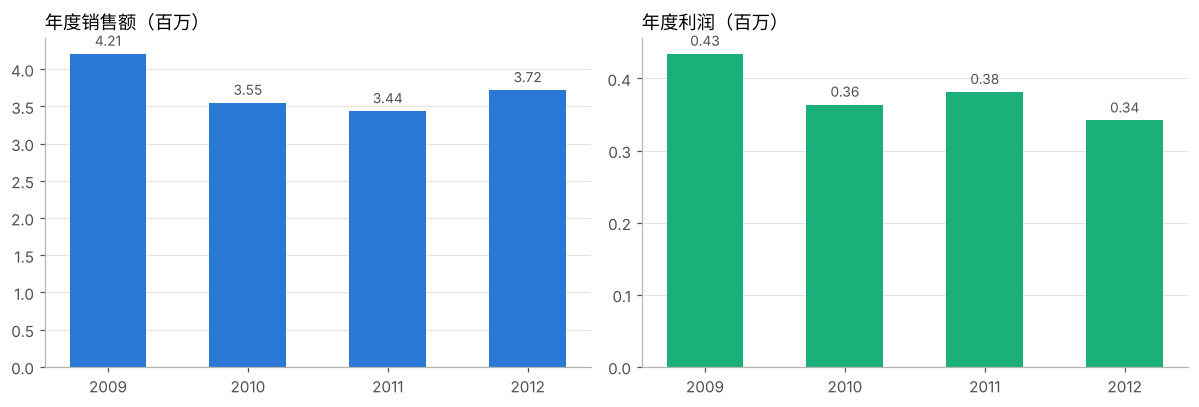

,销售额,利润,利润率
Year,,,
2009,"4,209,139","434,539",10.3%
2010,"3,549,681","363,871",10.3%
2011,"3,436,817","381,456",11.1%
2012,"3,719,964","341,902",9.2%


In [6]:
yearly = df.groupby('Year').agg(销售额=('Sales', 'sum'), 利润=('Profit', 'sum'))
yearly['利润率'] = yearly['利润'] / yearly['销售额']

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, color in zip(axes, ['销售额', '利润'], [BLUE, AQUA]):
    bars = ax.bar(yearly.index.astype(str), yearly[col] / 1e6, color=color, width=0.55)
    ax.bar_label(bars, fmt='%.2f', padding=3, color='#52514e', fontsize=9)
    ax.set_title(f'年度{col}（百万）', loc='left', fontsize=12)
    ax.grid(axis='x', visible=False)
save(fig, '01_yearly.png'); plt.show()
yearly.style.format({'销售额': '{:,.0f}', '利润': '{:,.0f}', '利润率': '{:.1%}'})

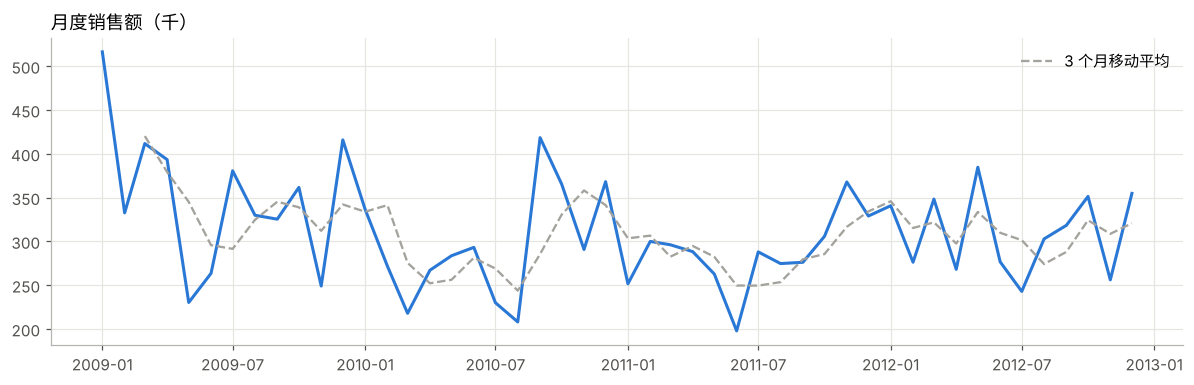

In [7]:
monthly = df.set_index('Order Date')['Sales'].resample('MS').sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(monthly.index, monthly / 1e3, color=BLUE, linewidth=2)
ax.plot(monthly.index, (monthly.rolling(3).mean()) / 1e3, color=GRAY, linewidth=1.5, linestyle='--', label='3 个月移动平均')
ax.set_title('月度销售额（千）', loc='left', fontsize=12)
ax.legend(frameon=False)
save(fig, '02_monthly.png'); plt.show()

**解读**：
- 销售额 2009 年最高（421 万），2010–2011 年下滑到 340 多万，2012 年小幅回升到 372 万，**仍比 2009 年低约 12%**。
- 利润率稳定在 9%–11%，但 **2012 年是 4 年最低（9.2%）**：销售额回升了，利润反而下降，说明增长的质量不高。
- 月度销售额在约 20 万到 52 万之间波动（相差约 2.6 倍），没有稳定的季节规律。

业务处于存量状态，提升利润要从结构上找空间，而不是指望规模增长。

## 4. 品类利润：钱从哪里赚、在哪里亏

In [8]:
cat = df.groupby('Product Category').agg(销售额=('Sales', 'sum'), 利润=('Profit', 'sum'))
cat['利润率'] = cat['利润'] / cat['销售额']
cat.sort_values('利润', ascending=False).style.format({'销售额': '{:,.0f}', '利润': '{:,.0f}', '利润率': '{:.1%}'})

,销售额,利润,利润率
Product Category,,,
Technology,"5,984,248","886,314",14.8%
Office Supplies,"3,752,762","518,021",13.8%
Furniture,"5,178,591","117,433",2.3%


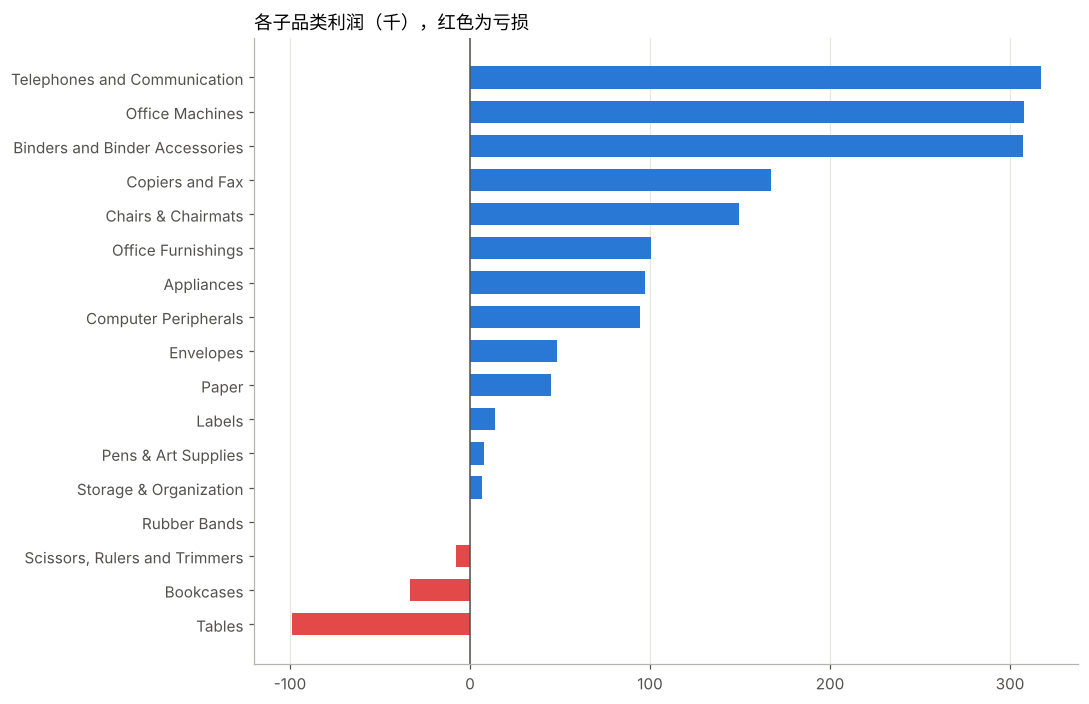

,销售额,利润,利润率
Product Sub-Category,,,
Tables,"1,896,008","-99,062",-5.2%
Bookcases,"822,652","-33,582",-4.1%
"Scissors, Rulers and Trimmers","80,996","-7,799",-9.6%
Rubber Bands,"15,007",-103,-0.7%


In [9]:
sub = df.groupby('Product Sub-Category').agg(销售额=('Sales', 'sum'), 利润=('Profit', 'sum')).sort_values('利润')
sub['利润率'] = sub['利润'] / sub['销售额']

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = [RED if v < 0 else BLUE for v in sub['利润']]
ax.barh(sub.index, sub['利润'] / 1e3, color=colors, height=0.65)
ax.axvline(0, color='#52514e', linewidth=1)
ax.set_title('各子品类利润（千），红色为亏损', loc='left', fontsize=12)
ax.grid(axis='y', visible=False)
save(fig, '03_subcategory_profit.png'); plt.show()
sub[sub['利润'] < 0].style.format({'销售额': '{:,.0f}', '利润': '{:,.0f}', '利润率': '{:.1%}'})

**解读**：
- **家具（Furniture）是最大的问题**：销售额 518 万，占总额约 35%，利润率却只有 **2.3%**；科技类和办公用品分别是 14.8% 和 13.8%。
- 家具的问题集中在两个子品类：**桌子（Tables）销售额 190 万、亏损 9.9 万；书柜（Bookcases）销售额 82 万、亏损 3.4 万**。两者合计亏掉 13.3 万，相当于公司总利润的近 9%，属于典型的“越卖越亏”。
- 利润贡献最大的是电话通讯、办公机器和文件夹（Binders），文件夹的利润率超过 30%。

**建议**：优先复盘桌子和书柜的定价、折扣和运费（大件商品运费高是常见原因），必要时提价或缩减品类；同时加大高利润率的小件办公用品的推广。

## 5. 折扣与利润的关系

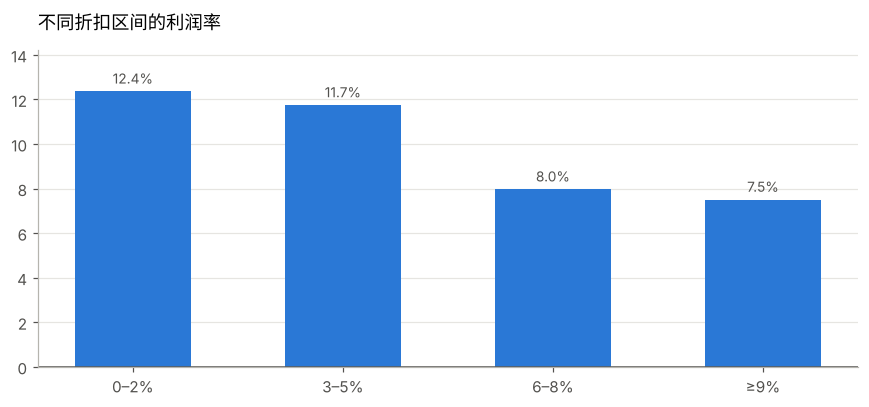

,订单数,销售额,利润,亏损订单占比,利润率
折扣区间,,,,,
0–2%,2327,"4,344,048","536,895",47.2%,12.4%
3–5%,2335,"4,082,477","479,477",48.8%,11.7%
6–8%,2209,"3,983,045","317,328",53.0%,8.0%
≥9%,1528,"2,506,031","188,068",56.1%,7.5%


In [10]:
# 折扣超过 10% 的订单只有 5 条，样本太少，并入最高一档
bins = [-0.001, 0.02, 0.05, 0.08, 0.25]
labels = ['0–2%', '3–5%', '6–8%', '≥9%']
df['折扣区间'] = pd.cut(df['Discount'], bins=bins, labels=labels)
disc = df.groupby('折扣区间', observed=True).agg(订单数=('Sales', 'size'), 销售额=('Sales', 'sum'), 利润=('Profit', 'sum'),
                                              亏损订单占比=('Profit', lambda s: (s < 0).mean()))
disc['利润率'] = disc['利润'] / disc['销售额']

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(disc.index.astype(str), disc['利润率'] * 100, color=[RED if v < 0 else BLUE for v in disc['利润率']], width=0.55)
ax.bar_label(bars, fmt='%.1f%%', padding=3, color='#52514e', fontsize=9)
ax.axhline(0, color='#52514e', linewidth=1)
ax.set_title('不同折扣区间的利润率', loc='left', fontsize=12, pad=14)
ax.set_ylim(0, disc['利润率'].max() * 100 * 1.15)
ax.grid(axis='x', visible=False)
save(fig, '04_discount.png'); plt.show()
disc.style.format({'销售额': '{:,.0f}', '利润': '{:,.0f}', '利润率': '{:.1%}', '亏损订单占比': '{:.1%}'})

**解读**：折扣越高，利润率越低：从 0–2% 档的 **12.4%** 一路降到 ≥9% 档的 **7.5%**；亏损订单占比也从 47% 升到 56%。折扣超过 5% 后利润率下滑明显（11.7% → 8.0%）。

**建议**：把常规折扣上限控制在 5% 左右，超过的需要审批，并按订单利润而不是销售额来考核销售。

## 6. 区域表现

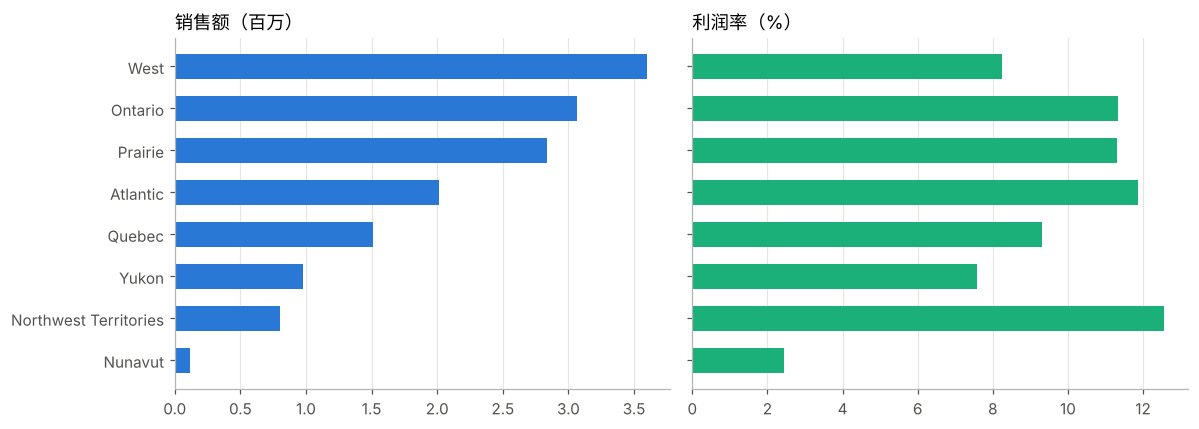

,销售额,利润,客户数,利润率
Region,,,,
West,"3,597,549","297,009",311,8.3%
Ontario,"3,063,212","346,869",281,11.3%
Prairie,"2,837,305","321,160",251,11.3%
Atlantic,"2,014,248","238,961",240,11.9%
Quebec,"1,510,195","140,427",170,9.3%
Yukon,"975,867","73,849",107,7.6%
Northwest Territories,"800,847","100,653",62,12.6%
Nunavut,"116,376","2,841",38,2.4%


In [11]:
reg = df.groupby('Region').agg(销售额=('Sales', 'sum'), 利润=('Profit', 'sum'), 客户数=('Customer Name', 'nunique'))
reg['利润率'] = reg['利润'] / reg['销售额']
reg = reg.sort_values('销售额')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].barh(reg.index, reg['销售额'] / 1e6, color=BLUE, height=0.6)
axes[0].set_title('销售额（百万）', loc='left', fontsize=12)
axes[1].barh(reg.index, reg['利润率'] * 100, color=[RED if v < 0 else AQUA for v in reg['利润率']], height=0.6)
axes[1].set_title('利润率（%）', loc='left', fontsize=12)
for ax in axes: ax.grid(axis='y', visible=False)
save(fig, '05_region.png'); plt.show()
reg.sort_values('销售额', ascending=False).style.format({'销售额': '{:,.0f}', '利润': '{:,.0f}', '利润率': '{:.1%}'})

**解读**：
- **West 区销售额最高（360 万），利润率却只有 8.3%**，明显低于 Ontario（11.3%）和 Prairie（11.3%），是最值得排查的区域。
- Northwest Territories 规模小（80 万）但利润率最高（12.6%），有加大投入的空间。
- Nunavut 销售额仅 12 万、利润率 2.4%，体量太小，维持即可。

## 7. 客户价值集中度（二八定律）

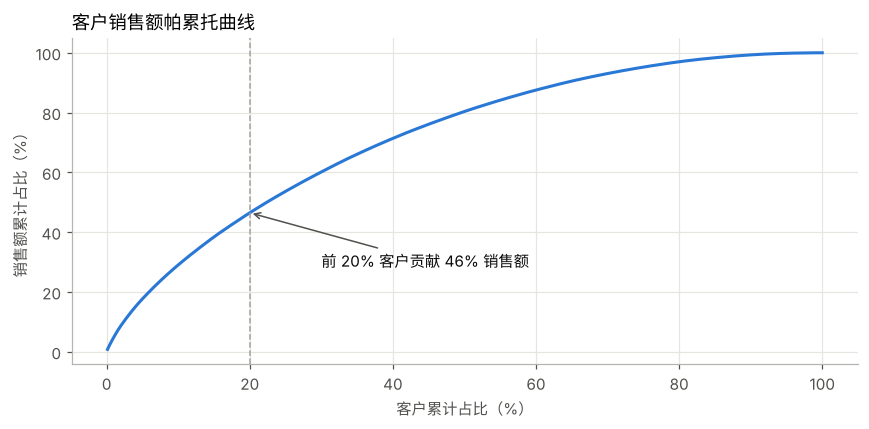

客户总数 795，前 20% 客户贡献 46.5% 的销售额


,销售额,利润,客户数,客均销售额,利润率
Customer Segment,,,,,
Corporate,"5,498,905","599,746",353,"15,578",10.9%
Home Office,"3,564,764","318,354",246,"14,491",8.9%
Consumer,"3,063,611","287,960",197,"15,551",9.4%
Small Business,"2,788,321","315,708",193,"14,447",11.3%


In [12]:
cust = df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False)
cum_share = cust.cumsum() / cust.sum()
top20_share = cum_share.iloc[int(len(cust) * 0.2) - 1]

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, len(cust) + 1) / len(cust) * 100
ax.plot(x, cum_share.values * 100, color=BLUE, linewidth=2)
ax.axvline(20, color=GRAY, linestyle='--', linewidth=1)
ax.annotate(f'前 20% 客户贡献 {top20_share:.0%} 销售额', xy=(20, top20_share * 100), xytext=(30, top20_share * 100 - 18),
            arrowprops=dict(arrowstyle='->', color='#52514e'), color='#0b0b0b', fontsize=10)
ax.set_xlabel('客户累计占比（%）'); ax.set_ylabel('销售额累计占比（%）')
ax.set_title('客户销售额帕累托曲线', loc='left', fontsize=12)
save(fig, '06_pareto.png'); plt.show()

seg = df.groupby('Customer Segment').agg(销售额=('Sales', 'sum'), 利润=('Profit', 'sum'), 客户数=('Customer Name', 'nunique'))
seg['客均销售额'] = seg['销售额'] / seg['客户数']
seg['利润率'] = seg['利润'] / seg['销售额']
print(f'客户总数 {len(cust)}，前 20% 客户贡献 {top20_share:.1%} 的销售额')
seg.sort_values('销售额', ascending=False).style.format({'销售额': '{:,.0f}', '利润': '{:,.0f}', '客均销售额': '{:,.0f}', '利润率': '{:.1%}'})

**解读**：
- 前 20% 的客户贡献了 **46.5%** 的销售额。有一定集中度，但远没到“二八”的程度，客户基础相对分散，单个大客户流失的风险不高。
- 企业客户（Corporate）是最大的客户群，销售额 550 万、占比约 37%；小企业（Small Business）利润率最高（11.3%）。

**建议**：维护好企业客户这个基本盘，同时针对利润率最高的小企业客户做定向获客。

## 8. 结论与建议

| # | 发现 | 建议 | 预期影响 |
|---|---|---|---|
| 1 | 销售额比 2009 年低 12%，2012 年利润率创新低（9.2%） | 增长靠结构优化，而不是单纯冲规模 | 方向性 |
| 2 | 家具利润率仅 2.3%，桌子 + 书柜亏损 13.3 万 | 复盘大件商品的定价和运费，必要时提价或缩减品类 | 扭亏可提升总利润约 9% |
| 3 | 折扣超过 5% 后利润率从 11.7% 降到 8% 以下 | 折扣上限 5%，超出需审批 | 约 44% 的销售额来自折扣超过 5% 的订单，收紧空间大 |
| 4 | West 区规模最大但利润率只有 8.3% | 排查 West 区的折扣和物流成本 | 拉到平均水平约可多赚 7 万 |
| 5 | 企业客户贡献 37% 的销售额，小企业利润率最高 | 维护企业客户，定向获取小企业客户 | 稳定收入、改善结构 |

> 第 4 条的估算：West 区利润率从 8.3% 提升到全公司平均的 10.2%，按 360 万销售额计算约多出 7 万利润。
>
> 本分析流程可以直接复用到任意“订单明细”类数据：替换数据文件和对应列名即可。